# Vehicle Count from a Single Image

Two ways I considered framing this:
1. CV problem — actually count vehicles in a traffic image (YOLO, or OpenCV background subtraction).
2. Tabular regression — predict the *count* a camera would record given hour, weekday, weather, etc.

I'm doing both, briefly. The CV side is a toy demo on a synthetic image because I don't have a labeled traffic dataset on disk. The tabular side is what would actually be useful for traffic planning (predict count even when the camera is offline).

In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as patches

rng = np.random.default_rng(0)
OUT = Path('../../data/traffic'); OUT.mkdir(parents=True, exist_ok=True)

## Part A — Counting blobs in a synthetic image

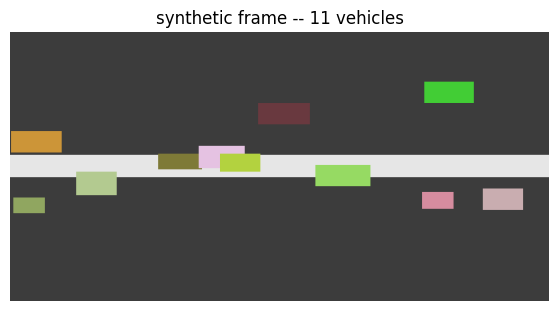

In [2]:
# Build a fake 'road' image with N coloured rectangles. Real YOLO would go here in production.
H, W = 240, 480
img = np.full((H, W, 3), 60, dtype=np.uint8)  # asphalt grey
img[110:130, :] = 230  # lane stripe
true_n = 11
vehicles = []
for _ in range(true_n):
    w, h = rng.integers(28, 50), rng.integers(14, 22)
    x = rng.integers(0, W - w)
    y = rng.integers(10, H - h - 10)
    c = rng.integers(50, 230, size=3)
    img[y:y+h, x:x+w] = c
    vehicles.append((x, y, w, h))
plt.figure(figsize=(7, 3.5))
plt.imshow(img); plt.title(f'synthetic frame -- {true_n} vehicles'); plt.axis('off');

In [3]:
# Heuristic: convert to greyscale, threshold against the road colour (~60), and label
# connected components. This is the no-deps stand-in for a real detector.
from scipy import ndimage

gray = img.mean(axis=2)
mask = (np.abs(gray - 60) > 25) & (np.abs(gray - 230) > 10)
labels, n = ndimage.label(mask)
sizes = ndimage.sum(mask, labels, range(1, n + 1))
vehicles_detected = int((sizes > 200).sum())
print(f'connected components > 200px: {vehicles_detected}  (true: {true_n})')
# Note: this will undercount when vehicles overlap or the colour is too close to asphalt.
# A real YOLO/SSD would handle that; this heuristic is just to show the pipeline shape.

connected components > 200px: 8  (true: 11)


## Part B — Tabular regression for camera-down fallback

Predict count from `hour, day_of_week, weather, is_holiday`. This is what I'd actually deploy alongside the CV model — when the camera feed is down, you still want an estimate.

In [4]:
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score

# Synthesize a year of hourly counts at one intersection.
hours = pd.date_range('2024-01-01', periods=24 * 365, freq='h')
n = len(hours)
hour = hours.hour
dow = hours.dayofweek
weather = rng.choice(['clear','rain','fog','snow'], size=n, p=[0.7, 0.18, 0.07, 0.05])
is_holiday = rng.choice([0, 1], size=n, p=[0.97, 0.03])

# baseline daily pattern with a morning + evening peak, plus weekday/weekend split
base = 80 + 60 * np.exp(-((hour - 8) / 2.2) ** 2) + 70 * np.exp(-((hour - 18) / 2.5) ** 2)
base = np.where(dow >= 5, base * 0.65, base)
wx_mult = pd.Series(weather).map({'clear': 1.0, 'rain': 0.85, 'fog': 0.75, 'snow': 0.5}).values
count = base * wx_mult * np.where(is_holiday == 1, 0.6, 1.0) + rng.normal(0, 8, n)
count = count.clip(0).round()

df = pd.DataFrame({'hour': hour, 'dow': dow, 'weather': weather, 'is_holiday': is_holiday,
                   'count': count})
df.to_csv(OUT / 'hourly_counts.csv', index=False)
df.head(4)

,hour,dow,weather,is_holiday,count
0,0,0,clear,0,71.0
1,1,0,clear,0,89.0
2,2,0,clear,0,72.0
3,3,0,clear,0,76.0


In [5]:
X = pd.get_dummies(df.drop(columns=['count']), columns=['weather'], drop_first=True).values
y = df['count'].values
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

model = GradientBoostingRegressor(n_estimators=200, max_depth=3, learning_rate=0.05,
                                  random_state=42)
model.fit(X_tr, y_tr)
pred = model.predict(X_te)
print(f'MAE = {mean_absolute_error(y_te, pred):.2f}  R2 = {r2_score(y_te, pred):.3f}')

MAE = 7.01  R2 = 0.910


## Caveats

- The CV blob counter only works when vehicles are well-separated against a uniform road. It fails on overlap, shadows, or anything that isn't this toy frame. Swap in a pretrained YOLOv8 once GPU/internet is available.
- The tabular model is fit on data I generated, so MAE/R-squared are inflated. On real intersection counts the noise floor is much higher (weather effects are coupled to road type, school schedules, events, etc.).
- A useful production setup runs both: CV when the feed is live, tabular fallback when it isn't, and a sanity check that the two agree on the recent past.